In [53]:
import time, re
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from nba_api.stats.endpoints import playerindex, leaguedashplayerstats


salaries = pd.read_csv('NbaPlayerSalaries.csv')
season_cols = ['2022/2023', '2023/2024', '2024/2025']

for col in season_cols:
    # Turns the String salary of NbaPlayerSalaries.csv into float for an easier time comparing to player stats
    salaries[col] = (salaries[col].astype(str).str.replace(r'[\$,\s]', '', regex=True).astype(float))

Pearson (Total PTS vs Total Salary):  r = 0.70, p = 2.6998889513736928e-64
Pearson (PPG vs Total Salary): r = 0.75, p = 7.259840531532599e-80
Spearman (PPG vs Total Salary): rho = 0.70, p = 1.1802444121515886e-65


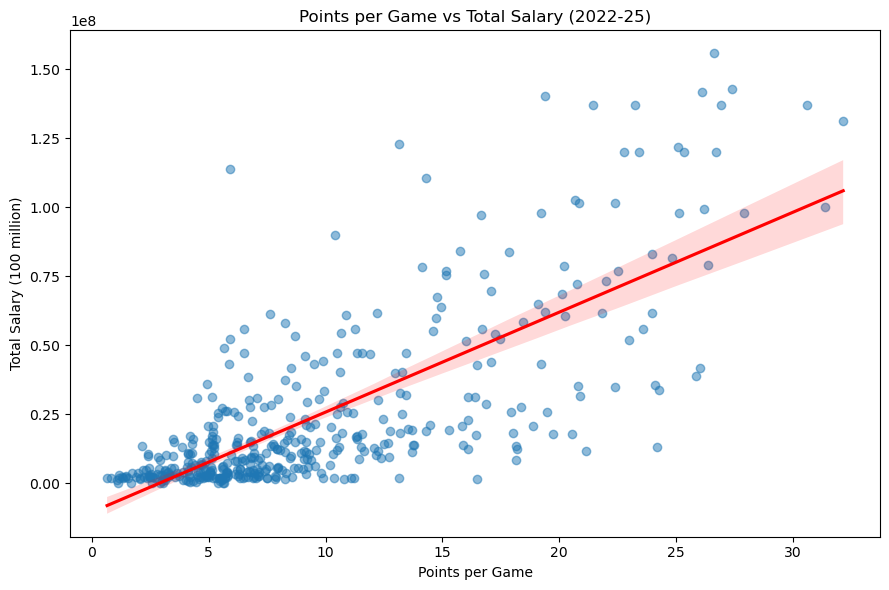

Slope: $3,618,365.60 extra salary per additional PPG
r = 0.75
t-test p-value = 7.259840531533728e-80
p < 0.05: reject H0. Scoring and salary are significantly correlated.


In [54]:
def season_start(starting_year):
    return f"{starting_year}-{str(starting_year + 1)[-2:]}"
    #Turns years into NBA season format i.e 2022 -> 2022-23 to correctly pull data

frames = []
for year in range(2022, 2025):
    df = leaguedashplayerstats.LeagueDashPlayerStats(
        season=season_start(year),
        per_mode_detailed="Totals",
        season_type_all_star="Regular Season",
    ).get_data_frames()[0]
    df["SEASON"] = season_start(year)
    frames.append(df)

all_seasons = pd.concat(frames, ignore_index=True)
combined = (
    all_seasons.groupby(["PLAYER_ID", "PLAYER_NAME"], as_index=False)[["GP", "MIN", "PTS", "REB", "AST"]]
        .sum().round(1)
)
combined = combined.merge(NBAdf[["PERSON_ID", "POSITION"]], left_on="PLAYER_ID", right_on="PERSON_ID", how="left",)

salaries['TOTAL_SALARY'] = salaries[season_cols].sum(axis=1)
salaries['KEY'] = salaries['Player Name']
combined['KEY'] = combined['PLAYER_NAME']

data = combined.merge(salaries[['KEY', 'TOTAL_SALARY']], on='KEY', how='inner')

# Drop players with no salary on record and players with barely any playing time
data = data[(data['TOTAL_SALARY'] > 0) & (data['GP'] >= 20)].copy()

data['PPG'] = data['PTS'] / data['GP']

r, p = stats.pearsonr(data['PTS'], data['TOTAL_SALARY'])
print(f"Pearson (Total PTS vs Total Salary):  r = {r:.2f}, p = {p}")

r_ppg, p_ppg = stats.pearsonr(data['PPG'], data['TOTAL_SALARY'])
print(f"Pearson (PPG vs Total Salary): r = {r_ppg:.2f}, p = {p_ppg}")

rho, p_rho = stats.spearmanr(data['PPG'], data['TOTAL_SALARY'])
print(f"Spearman (PPG vs Total Salary): rho = {rho:.2f}, p = {p_rho}")

# Scatter plot with regression line
fig, ax = plt.subplots(figsize=(9, 6))
sns.regplot(data=data, x='PPG', y='TOTAL_SALARY', ax=ax, scatter_kws={'alpha': 0.5}, line_kws={'color': 'red'})
ax.set_title(f'Points per Game vs Total Salary (2022-25)')
ax.set_xlabel('Points per Game')
ax.set_ylabel('Total Salary (100 million)')
plt.tight_layout()
plt.show()

# Hypothesis test: Is there a correlation between scoring and salary?
alpha = 0.05

result = stats.linregress(data['PPG'], data['TOTAL_SALARY'])
print(f"Slope: ${result.slope:,.2f} extra salary per additional PPG")
print(f"r = {result.rvalue:.2f}")
print(f"t-test p-value = {result.pvalue}")

if result.pvalue < alpha:
    print(f"p < {alpha}: reject H0. Scoring and salary are significantly correlated.")
else:
    print(f"p >= {alpha}: fail to reject H0. No significant evidence of a relationship.")